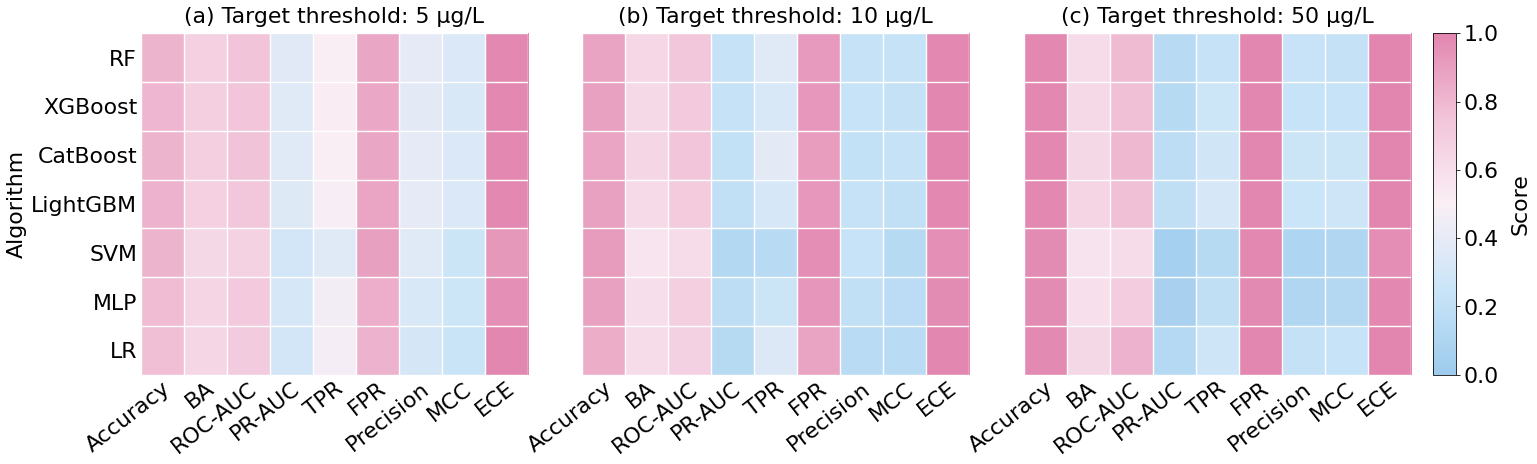

Saved 300-DPI heatmap: E:\NO-NC\submission\revise\three_thresholds_model_metrics_heatmap.jpg


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

RESULTS_DIR = Path("E:/NO-NC/normalization/revise/reviewer3_threshold_results")
OUTPUT_DIR = Path(r"E:\NO-NC\submission\revise")
OUTPUT_JPG = OUTPUT_DIR / "three_thresholds_model_metrics_heatmap.jpg"

THRESHOLDS = [5, 10, 50]
FEATURE_SETS = {"all", "correlation", "SelectKBest", "PFI"}
MODEL_ROWS = [
    ("RF", "RandomForestRegressor"),
    ("XGBoost", "XGBoostRegressor"),
    ("CatBoost", "CatBoostRegressor"),
    ("LightGBM", "LightGBMRegressor"),
    ("SVM", "SVR"),
    ("MLP", "MLPRegressor"),
    ("LR", "LogisticRegression"),
]
METRICS = [
    ("Accuracy", "OOF_Accuracy", False),
    ("BA", "OOF_Balanced_accuracy", False),
    ("ROC-AUC", "OOF_ROC_AUC", False),
    ("PR-AUC", "OOF_PR_AUC", False),
    ("TPR", "OOF_TPR", False),
    ("FPR", "OOF_FPR", True),
    ("Precision", "OOF_Precision", False),
    ("MCC", "OOF_MCC", False),
    ("ECE", "OOF_ECE_10_equal_width_bins", True),
]

# (4) 统一字号配置变量，便于后续灵活调整
FONT_SIZE_CONFIG = {
    "font_family": "DejaVu Sans",
    "base": 22,          # 基础字号
    "axes_title": 22,    # 子图标题字号
    "tick": 22,          # 坐标轴刻度字号
    "label": 22,         # 坐标轴轴标签/Colorbar标签字号
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
raw_values = {}

for threshold in THRESHOLDS:
    raw_matrix = np.zeros((len(MODEL_ROWS), len(METRICS)), dtype=float)
    for row_idx, (short_name, model_name) in enumerate(MODEL_ROWS):
        csv_path = (
            RESULTS_DIR / f"threshold_{threshold}" / "per_model_results" / f"{model_name}_cv_summary.csv"
        )
        if not csv_path.exists():
            raise FileNotFoundError(f"Missing CV summary: {csv_path}")
        df = pd.read_csv(csv_path)
        if set(df["feature_set"].astype(str)) != FEATURE_SETS or len(df) != 4:
            raise ValueError(
                f"Expected exactly the four feature sets {sorted(FEATURE_SETS)} "
                f"for {model_name}, threshold {threshold}; found {df['feature_set'].tolist()}"
            )
        for col_idx, (_, metric_col, lower_is_better) in enumerate(METRICS):
            if metric_col not in df.columns:
                raise KeyError(f"Missing metric column {metric_col} in {csv_path}")
            raw_matrix[row_idx, col_idx] = float(df[metric_col].mean())
    raw_values[threshold] = raw_matrix

# (5) 自定义马卡龙色系色图 (Macaron / Pastel Colormap)
# 从柔和的马卡龙粉紫 -> 马卡龙浅黄 -> 马卡龙薄荷绿
macaron_colors = ["#9DCBED", "#CAE5F8", "#FAEFF5", "#F2C5DA", "#E286AF"]
# macaron_colors = ["#F4C2C2", "#FDFD96", "#B4E197", "#88E0EF"]
macaron_cmap = LinearSegmentedColormap.from_list("macaron_RdYlGn", macaron_colors, N=256)

# 图形整体样式设置
plt.rcParams.update({
    "font.family": FONT_SIZE_CONFIG["font_family"],
    "font.size": FONT_SIZE_CONFIG["base"],
    "axes.titlesize": FONT_SIZE_CONFIG["axes_title"],
    "xtick.labelsize": FONT_SIZE_CONFIG["tick"],
    "ytick.labelsize": FONT_SIZE_CONFIG["tick"],
})

# 创建 3 面板画布 (调整留白，使 colorbar 高度与热力图完美对齐)
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), sharey=True)

panel_tags = ["(a)", "(b)", "(c)"]
row_labels = [short for short, _ in MODEL_ROWS]
metric_labels = [label for label, _, _ in METRICS]
image = None

for ax, threshold, tag in zip(axes, THRESHOLDS, panel_tags):
    matrix = raw_values[threshold].copy()
    color_matrix = matrix.copy()
    
    for col_idx, (_, _, lower_is_better) in enumerate(METRICS):
        if lower_is_better:
            color_matrix[:, col_idx] = 1.0 - color_matrix[:, col_idx]

    # (1) 去掉数字，仅通过 imshow 渲染热力图颜色
    image = ax.imshow(color_matrix, cmap=macaron_cmap, vmin=0, vmax=1, aspect="auto")
    
    # (3) 去掉加粗 (去掉 fontweight="bold")
    ax.set_title(f"{tag} Target threshold: {threshold} µg/L", pad=10)
    ax.set_xticks(np.arange(len(metric_labels)))
    ax.set_xticklabels(metric_labels, rotation=38, ha="right", rotation_mode="anchor")
    ax.set_yticks(np.arange(len(row_labels)))
    ax.set_yticklabels(row_labels)
    
    ax.set_xticks(np.arange(-0.5, len(metric_labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.4)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.tick_params(axis="both", length=0)
    
    # (1) 原本绘制数字的循环已移除
    
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel("Algorithm", fontsize=FONT_SIZE_CONFIG["label"])

# (7) 动态精准计算并拉伸 Colorbar 高度使其与热力图区域严格对齐
fig.subplots_adjust(left=0.06, right=0.90, bottom=0.15, top=0.88, wspace=0.14)

# 获取主图坐标用于对齐 colorbar
pos0 = axes[0].get_position()
pos2 = axes[2].get_position()
cax_left = pos2.x1 + 0.015
cax_bottom = pos0.y0
cax_width = 0.015
cax_height = pos0.height

cax = fig.add_axes([cax_left, cax_bottom, cax_width, cax_height])
cbar = fig.colorbar(image, cax=cax)

# (3, 6) 去掉加粗，并将标签修改为 "Score"
cbar.set_label("Score", rotation=90, labelpad=12, fontsize=FONT_SIZE_CONFIG["label"])
cbar.ax.tick_params(labelsize=FONT_SIZE_CONFIG["tick"])

# 保存并展示图片
fig.savefig(OUTPUT_JPG, dpi=300, format="jpg", bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)
print(f"Saved 300-DPI heatmap: {OUTPUT_JPG}")